# Deep Neural Network for Student Academic Performance Prediction

## Project Objective

This notebook develops a Deep Neural Network (DNN) to classify student academic performance using the UCI Portuguese student performance dataset.

The original final grade (`G3`) is converted into three categories:

- **Low:** `G3` from 0 to 9
- **Average:** `G3` from 10 to 13
- **Good:** `G3` from 14 to 20

`G1`, `G2`, and `G3` are excluded from model inputs so that predictions do not rely on the recorded grades. The original dataset is explored separately in the EDA notebook.


In [17]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout

## Dataset Loading

In [18]:
df = pd.read_csv("../data/student-por.csv", sep=";")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## Performance Category Creation

In [19]:
def categorize_performance(g3):
    if g3 <= 9:
        return "Low"
    elif g3 <= 13:
        return "Average"
    else:
        return "Good"

df["performance_category"] = df["G3"].apply(categorize_performance)

print(df["performance_category"].value_counts())

performance_category
Average    355
Good       194
Low        100
Name: count, dtype: int64


## Feature and Target Selection

In [20]:
X = df.drop(columns=["G1", "G2", "G3", "performance_category"])
y = df["performance_category"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (649, 30)
y shape: (649,)


## Dataset Splitting Strategy

The dataset has 649 students. We first create a stratified **80% training pool (519 students)** and **20% test set (130 students)**. The training pool is then divided into **415 training** and **104 validation** students using another stratified split.

- **Training:** learn model parameters and fit preprocessing transformations.
- **Validation:** monitor training, select settings, and evaluate development-stage performance.
- **Test:** reserved from further tuning for final evaluation.

**Experimental limitation:** The test set was used during preliminary exploration before this cleaned workflow. Those earlier test results are not used for further model selection.


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (519, 30)
X_test: (130, 30)
y_train: (519,)
y_test: (130,)


In [22]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 13
Categorical features: 17


## Improved Training and Validation Setup

We divide the original training pool into training and validation sets.

We use stratified splitting to preserve the approximate distribution
of performance categories.

Preprocessing is fitted only on the training subset to prevent
validation-data leakage.

In [23]:

from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (415, 30)
Validation: (104, 30)
Testing: (130, 30)


## Training-Only Preprocessing

Numerical features are standardized using `StandardScaler`, and categorical features are converted to indicator columns using `OneHotEncoder`. We **fit** these transformations on the 415-student training subset only, then **transform** validation data with the same fitted preprocessor. This avoids leaking validation information into preprocessing.


In [24]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor_final = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Learn preprocessing rules from training data only
X_train_final_processed = preprocessor_final.fit_transform(
    X_train_final
)

# Apply the same rules to validation data
X_val_processed = preprocessor_final.transform(
    X_val
)

print("Training:", X_train_final_processed.shape)
print("Validation:", X_val_processed.shape)

Training: (415, 56)
Validation: (104, 56)


## Target Encoding and Class Imbalance

`LabelEncoder` converts the three category names into integer targets for sparse categorical cross-entropy. Balanced class weights are calculated **only from training labels**, giving underrepresented categories more weight during training.


In [25]:
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Encode target labels
label_encoder_final = LabelEncoder()

y_train_final_encoded = label_encoder_final.fit_transform(
    y_train_final
)

y_val_encoded = label_encoder_final.transform(
    y_val
)

# Calculate class weights using training labels only
classes = np.unique(y_train_final_encoded)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_final_encoded
)

class_weights_final = dict(zip(classes, weights))

print("Class Mapping:")
for i, label in enumerate(label_encoder_final.classes_):
    print(f"{label} -> {i}")

print("\nClass Weights:")
print(class_weights_final)

print("\nTarget Shapes:")
print("Training:", y_train_final_encoded.shape)
print("Validation:", y_val_encoded.shape)

Class Mapping:
Average -> 0
Good -> 1
Low -> 2

Class Weights:
{np.int64(0): np.float64(0.6093979441997063), np.int64(1): np.float64(1.1155913978494623), np.int64(2): np.float64(2.1614583333333335)}

Target Shapes:
Training: (415,)
Validation: (104,)


## Deep Neural Network Architecture

The preprocessed input contains **56 features**. The network has two hidden layers of **64** and **32** neurons with **ReLU** activations, followed by **dropout (0.2)** after each hidden layer. The output uses **3 Softmax neurons** for the three performance categories.

- **Dense layers:** learn combinations of input features.
- **ReLU:** enables learning nonlinear patterns.
- **Dropout:** randomly disables units during training to help reduce overfitting.
- **Softmax:** produces probabilities across the three classes.
- **Adam (learning rate 0.001):** updates the model weights.
- **Sparse categorical cross-entropy:** works with integer-encoded class labels.

The 64–32 architecture is a practical starting configuration for a small dataset, not a proven optimal architecture.


In [ ]:
# Provisional hyperparameters from initial experiments:
# Learning rate = 0.001
# Dropout rate = 0.2
# These experiments used an earlier validation setup.
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
def build_dnn_dropout(dropout_rate):
    model = Sequential([
        Input(shape=(56,)),

        Dense(64, activation="relu"),
        Dropout(dropout_rate),

        Dense(32, activation="relu"),
        Dropout(dropout_rate),

        Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

### Final Hyperparameter Selection

Manual hyperparameter tuning was performed using a separate experiment notebook.

The experiments compared learning rates of 0.0005, 0.001 and 0.002, and dropout rates of 0.2, 0.3 and 0.4.

All updated experiments used Early Stopping with a patience of 10 epochs and restored the weights corresponding to the lowest validation loss.

The selected configuration was:

- **Learning rate:** 0.001
- **Dropout rate:** 0.2
- **Batch size:** 32
- **Hidden layers:** 64 and 32 neurons
- **Optimizer:** Adam

This configuration achieved 58.65% restored validation accuracy and approximately 0.5523 macro F1 during tuning.

The selected settings are provisional because the validation dataset is relatively small and the performance differences between the leading configurations are minor.

## Improved DNN Training with Early Stopping

The model trains for up to **100 epochs**, with a **batch size of 32**, balanced class weights, and validation monitoring. `EarlyStopping` watches **validation loss** with a patience of **10 epochs**, and `restore_best_weights=True` restores the weights from the epoch with the lowest validation loss.

In the selected DNN experiment, training stopped after 23 epochs. Early Stopping restored the weights corresponding to the minimum validation loss of approximately 0.9428.


In [27]:
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build model using our existing function
improved_model = build_dnn_dropout(0.2)

# Early stopping configuration
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

improved_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         3,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,827 (22.76 KB)

 Trainable params: 5,827 (22.76 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
improved_history = improved_model.fit(
    X_train_final_processed,
    y_train_final_encoded,

    validation_data=(
        X_val_processed,
        y_val_encoded
    ),

    epochs=100,
    batch_size=32,

    class_weight=class_weights_final,
    callbacks=[early_stopping],

    verbose=1
)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.3831 - loss: 1.1309 - val_accuracy: 0.3846 - val_loss: 1.0622
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4145 - loss: 1.0535 - val_accuracy: 0.4327 - val_loss: 1.0411
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4289 - loss: 1.0417 - val_accuracy: 0.4423 - val_loss: 1.0231
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4482 - loss: 0.9659 - val_accuracy: 0.4615 - val_loss: 1.0058
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4819 - loss: 0.9534 - val_accuracy: 0.4808 - val_loss: 0.9861
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4916 - loss: 0.9127 - val_accuracy: 0.5096 - val_loss: 0.9710
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5181 - loss: 0.8853 - val_accuracy: 0.5288 - val_loss: 0.9577
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5325 - loss: 0.8576 - val_accuracy: 0.538

## Training Curves

The next two graphs compare training and validation performance across epochs. A widening gap between training and validation performance can suggest overfitting; rising validation loss while training loss falls is another warning sign.


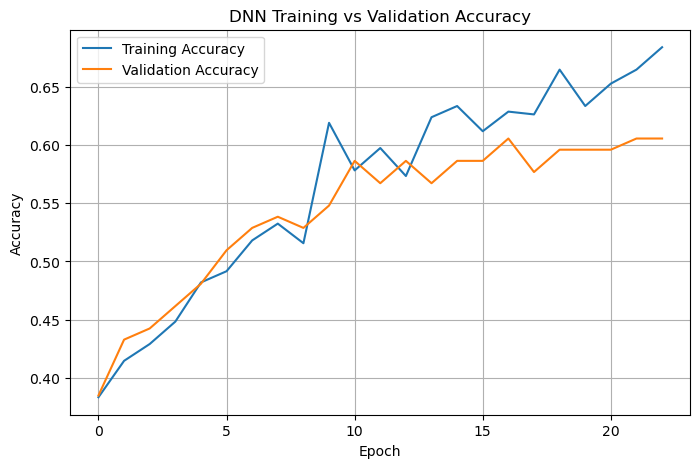

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(improved_history.history["accuracy"], label="Training Accuracy")
plt.plot(improved_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DNN Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

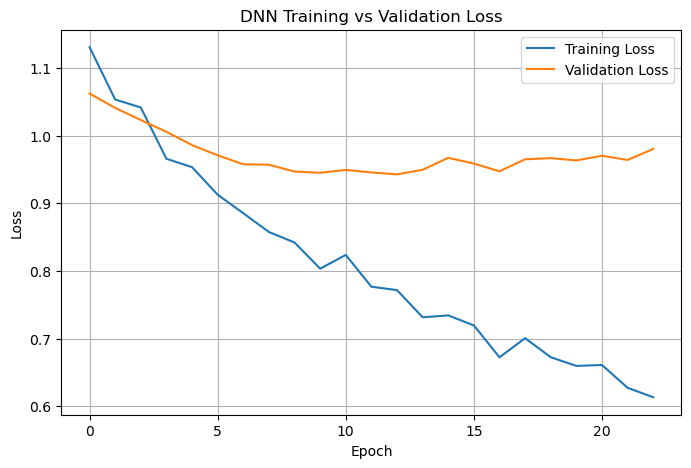

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(improved_history.history["loss"], label="Training Loss")
plt.plot(improved_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DNN Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [31]:
print("Epochs completed:", len(improved_history.history["loss"]))

print("Best Validation Accuracy:",
      max(improved_history.history["val_accuracy"]))

print("Best Validation Loss:",
      min(improved_history.history["val_loss"]))

val_loss, val_accuracy = improved_model.evaluate(
    X_val_processed,
    y_val_encoded,
    verbose=0
)

print("Restored Model Validation Accuracy:", val_accuracy)
print("Restored Model Validation Loss:", val_loss)

Epochs completed: 23
Best Validation Accuracy: 0.6057692170143127
Best Validation Loss: 0.942819356918335
Restored Model Validation Accuracy: 0.5865384340286255
Restored Model Validation Loss: 0.942819356918335


## DNN Validation Evaluation

We evaluate the trained model using the validation dataset.

We calculate:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

Special attention is given to the Low-performing category because
identifying academically at-risk students is an important objective.

In [32]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Predict probabilities on validation data
y_val_probabilities = improved_model.predict(X_val_processed)

# Convert probabilities into predicted class labels
y_val_pred = np.argmax(y_val_probabilities, axis=1)

# Print classification report
print("Classification Report:\n")

print(
    classification_report(
        y_val_encoded,
        y_val_pred,
        target_names=label_encoder_final.classes_,
        zero_division=0
    )
)

# Print confusion matrix
print("\nConfusion Matrix:\n")

print(confusion_matrix(y_val_encoded, y_val_pred))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Classification Report:

              precision    recall  f1-score   support

     Average       0.67      0.54      0.60        57
        Good       0.64      0.74      0.69        31
         Low       0.32      0.44      0.37        16

    accuracy                           0.59       104
   macro avg       0.54      0.57      0.55       104
weighted avg       0.61      0.59      0.59       104


Confusion Matrix:

[[31 12 14]
 [ 7 23  1]
 [ 8  1  7]]
